In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

x_train, y_train = train_df['msg'], train_df['label']
x_test, y_test = test_df['msg'], test_df['label']

In [5]:
train_df.head()

,label,msg
0,ham,well done blimey exercise yeah kinda remember ...
1,ham,sno competition
2,ham,chikku nt yet ya im free
3,spam,hi im sue years old work lapdancer love sex te...
4,spam,want anytime network mins text new video phone...


In [6]:
test_df.head()

,label,msg
0,spam,u secret admirer reveal thinks u r special cal...
1,ham,evo download flash jealous
2,spam,wow boys r back take uk tour win vip tickets p...
3,ham,r u continent
4,ham,sorry battery died come im getting gram wheres...


In [7]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LinearSVC(C=1.0, max_iter=1000, random_state=42))
])

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_scores = cross_val_score(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Baseline CV F1 Macro:", baseline_scores.mean())

Baseline CV F1 Macro: 0.9472850006517394


In [9]:
balanced_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

balanced_scores = cross_val_score(
    balanced_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Balanced CV F1 Macro:", balanced_scores.mean())

Balanced CV F1 Macro: 0.9473776396505483


In [10]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Macro:", grid_search.best_score_)

Best Parameters: {'model__C': 10, 'model__class_weight': None}
Best CV F1 Macro: 0.947783164559385


In [11]:
best_svm = grid_search.best_estimator_

vocab_size = len(best_svm.named_steps['tfidf'].vocabulary_)

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 7213


In [12]:
y_pred = best_svm.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9874152952565344

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       902
        spam       0.98      0.92      0.95       131

    accuracy                           0.99      1033
   macro avg       0.98      0.96      0.97      1033
weighted avg       0.99      0.99      0.99      1033



Confusion Matrix:
[[899   3]
 [ 10 121]]


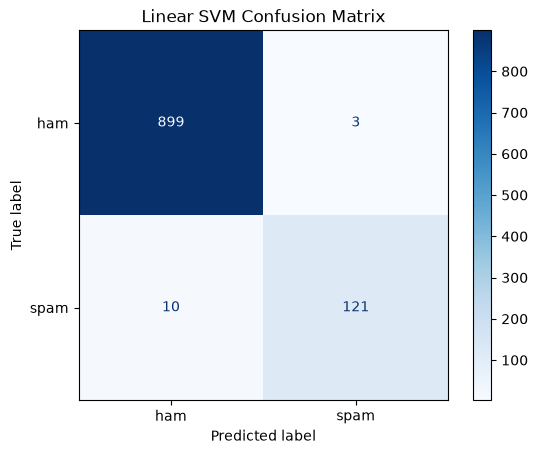

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=best_svm.classes_)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_svm.classes_
)

disp.plot(cmap='Blues')
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [14]:
joblib.dump(best_svm, '../models/linear_svm.pkl')

print("Linear SVM model saved successfully.")

Linear SVM model saved successfully.
